<a href="https://colab.research.google.com/github/piyush2500/Lab_work-Machine-learning/blob/main/DBSCAN_ca2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

uploaded = files.upload()
df = pd.read_csv(io.BytesIO(uploaded[next(iter(uploaded))]), sep=None, engine="python")
print("Dataset shape:", df.shape)

Saving marketing_campaign.csv to marketing_campaign.csv
Dataset shape: (2240, 29)


In [2]:
data = df.copy()

# Customer tenure in days
data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], dayfirst=True, errors="coerce")
data["Customer_Tenure_Days"] = (data["Dt_Customer"].max() - data["Dt_Customer"]).dt.days

data = data.drop(columns=["ID", "Dt_Customer", "Z_CostContact", "Z_Revenue", "Response"], errors="ignore")

numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
categorical_cols = data.select_dtypes(include="object").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical_cols),
])

X = preprocessor.fit_transform(data)
print("Features after encoding:", X.shape[1])

Features after encoding: 36


In [3]:
dbscan_labels = DBSCAN(eps=4.0, min_samples=10).fit_predict(X)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int((dbscan_labels == -1).sum())

print(f"Clusters (excluding noise): {n_clusters}")
print(f"Noise points: {n_noise} ({100 * n_noise / len(dbscan_labels):.2f}%)")
print(pd.Series(dbscan_labels, name="count").value_counts().sort_index())

Clusters (excluding noise): 5
Noise points: 255 (11.38%)
count
-1     255
 0    1900
 1      41
 2      10
 3      11
 4      23
Name: count, dtype: int64


Variance explained in 2D: 35.08%


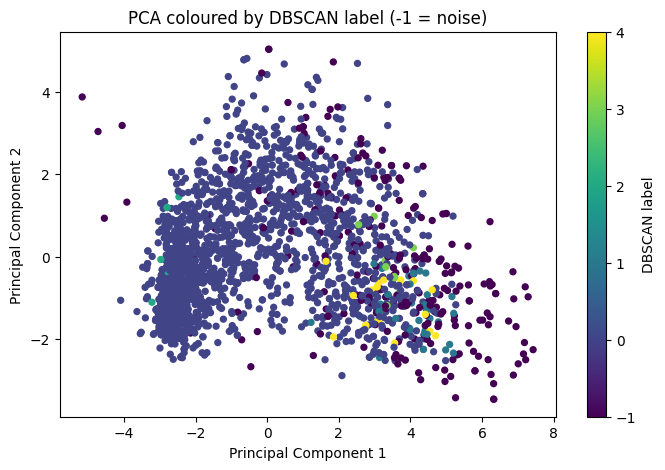

In [4]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print(f"Variance explained in 2D: {pca.explained_variance_ratio_.sum() * 100:.2f}%")

plt.figure(figsize=(8, 5))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, s=18)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA coloured by DBSCAN label (-1 = noise)")
plt.colorbar(sc, label="DBSCAN label")
plt.show()